# Complete Scikit-learn Workflow: Pipelines, Modeling, Evaluation, Interpretation, and Clustering




## Part A — Supervised Learning Pipeline

### A.1 Setup and imports

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, classification_report
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
%matplotlib inline

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df.rename(columns={"target": "malignant"}, inplace=True)
# Note: in sklearn's encoding, target=0 -> malignant, target=1 -> benign.

rng = np.random.default_rng(RANDOM_STATE)
df["clinic"] = rng.choice(["Clinic_A", "Clinic_B", "Clinic_C"], size=len(df), p=[0.5, 0.3, 0.2])

for col in ["mean radius", "mean texture", "mean smoothness"]:
    mask = rng.random(len(df)) < 0.05
    df.loc[mask, col] = np.nan

mask_cat = rng.random(len(df)) < 0.03
df.loc[mask_cat, "clinic"] = np.nan

print("Dataset shape:", df.shape)
print("\nMissing values per column (non-zero only):")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nClass balance:")
print(df["malignant"].value_counts())
df.head()

Dataset shape: (569, 32)

Missing values per column (non-zero only):
mean radius        32
mean texture       21
mean smoothness    30
clinic             13
dtype: int64

Class balance:
malignant
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant,clinic
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Clinic_B
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Clinic_A
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Clinic_C
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Clinic_B
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Clinic_A


In [3]:
X = df.drop(columns=["malignant"])
y = df["malignant"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train size: {X_train.shape}, Test size: {X_test.shape}")

Train size: (455, 31), Test size: (114, 31)


In [4]:
numeric_features = X.select_dtypes(include=["float64", "int64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])

print(f"Numeric features ({len(numeric_features)}): {numeric_features[:5]} ...")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

Numeric features (30): ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness'] ...
Categorical features (1): ['clinic']


In [5]:
pipe_logreg = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
])

pipe_rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=RANDOM_STATE)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grid_logreg = {"classifier__C": [0.01, 0.1, 1, 10]}
param_grid_rf = {
    "classifier__n_estimators": [100, 300],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_leaf": [1, 3],
}

grid_logreg = GridSearchCV(pipe_logreg, param_grid_logreg, cv=cv, scoring="roc_auc", n_jobs=-1)
grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=cv, scoring="roc_auc", n_jobs=-1)

grid_logreg.fit(X_train, y_train)
grid_rf.fit(X_train, y_train)

print(f"Logistic Regression -> best CV ROC-AUC: {grid_logreg.best_score_:.4f}, params: {grid_logreg.best_params_}")
print(f"Random Forest       -> best CV ROC-AUC: {grid_rf.best_score_:.4f}, params: {grid_rf.best_params_}")

best_name, best_grid = max(
    [("Logistic Regression", grid_logreg), ("Random Forest", grid_rf)],
    key=lambda t: t[1].best_score_
)
best_model = best_grid.best_estimator_
print(f"\n>>> Selected model: {best_name} (CV ROC-AUC={best_grid.best_score_:.4f})")

Logistic Regression -> best CV ROC-AUC: 0.9948, params: {'classifier__C': 0.1}
Random Forest       -> best CV ROC-AUC: 0.9912, params: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}

>>> Selected model: Logistic Regression (CV ROC-AUC=0.9948)


### Evaluation on the held-out test set

We report the standard classification metrics, then visualize the confusion matrix and ROC curve.

In [7]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_proba):.4f}")
print()
print(classification_report(y_test, y_pred, target_names=["malignant(0)", "benign(1)"]))

Accuracy : 0.9737
Precision: 0.9726
Recall   : 0.9861
F1-score : 0.9793
ROC-AUC  : 0.9944

              precision    recall  f1-score   support

malignant(0)       0.98      0.95      0.96        42
   benign(1)       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



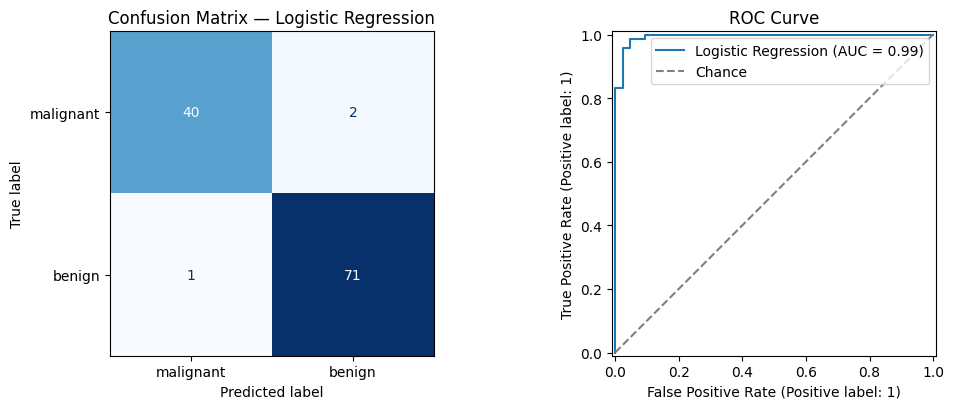

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["malignant", "benign"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion Matrix — {best_name}")

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name=best_name)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axes[1].set_title("ROC Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
cv_scores = cross_val_score(best_model, X_train, y_train, cv=cv, scoring="accuracy")
print(f"5-fold CV accuracy on training data: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")

5-fold CV accuracy on training data: 0.9824 +/- 0.0088


### Interpretation

**Model-specific interpretation:**

**Model-agnostic interpretation:**  

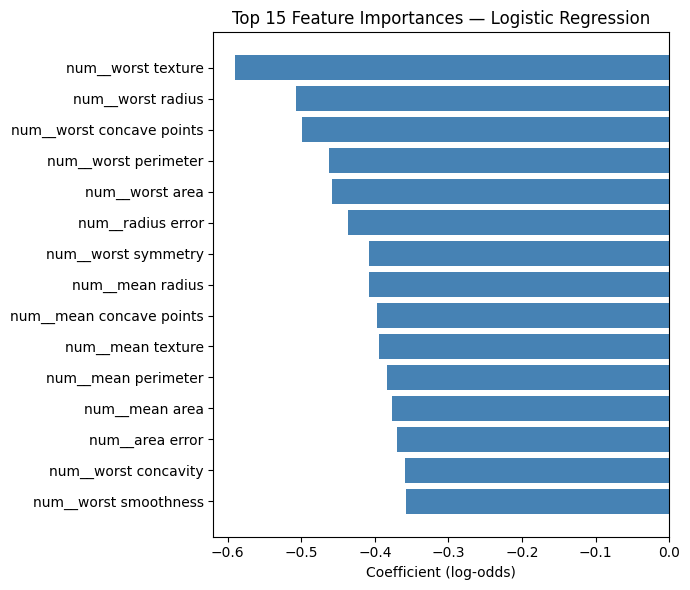

In [9]:
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()
clf = best_model.named_steps["classifier"]

if hasattr(clf, "coef_"):
    importances = clf.coef_[0]
    imp_label = "Coefficient (log-odds)"
else:
    importances = clf.feature_importances_
    imp_label = "Impurity-based importance"

order = np.argsort(np.abs(importances))[::-1][:15]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(np.array(feature_names)[order][::-1], importances[order][::-1], color="steelblue")
ax.set_xlabel(imp_label)
ax.set_title(f"Top 15 Feature Importances — {best_name}")
plt.tight_layout()
plt.show()

---
## Part B — Clustering: K-Means, Hierarchical, DBSCAN



In [11]:
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage

data = load_wine(as_frame=True)
X_wine = data.frame.drop(columns=["target"])
y_true = data.frame["target"]  # held out; used only for external validation at the end

print("Dataset shape:", X_wine.shape)
print("True class counts (reference only):")
print(y_true.value_counts().sort_index())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_wine)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f"\nPCA explained variance ratio (2 comps): {pca.explained_variance_ratio_.sum():.3f}")

Dataset shape: (178, 13)
True class counts (reference only):
target
0    59
1    71
2    48
Name: count, dtype: int64

PCA explained variance ratio (2 comps): 0.554


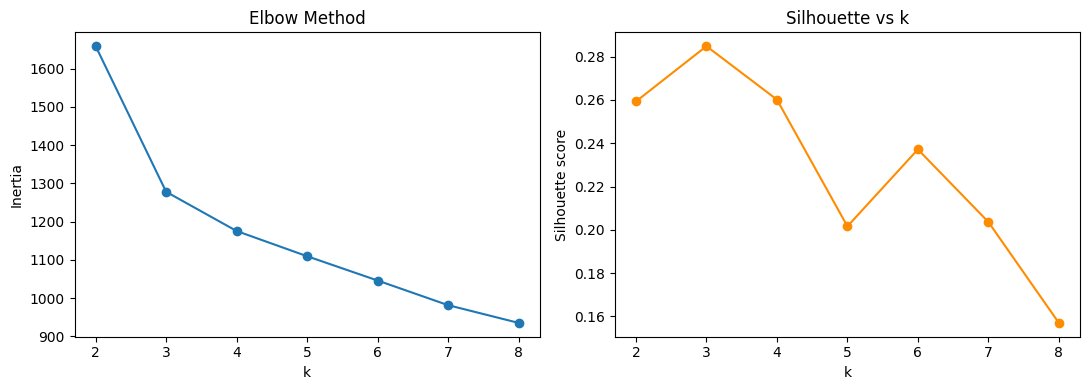

Best k by silhouette score: 3 (score=0.285)


In [12]:
inertias, sil_scores_km = [], []
k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores_km.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(k_range), inertias, marker="o")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia"); axes[0].set_title("Elbow Method")
axes[1].plot(list(k_range), sil_scores_km, marker="o", color="darkorange")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette score"); axes[1].set_title("Silhouette vs k")
plt.tight_layout()
plt.show()

best_k = list(k_range)[int(np.argmax(sil_scores_km))]
print(f"Best k by silhouette score: {best_k} (score={max(sil_scores_km):.3f})")

kmeans_final = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
labels_kmeans = kmeans_final.fit_predict(X_scaled)

### Hierarchical (Agglomerative) Clustering — dendrogram


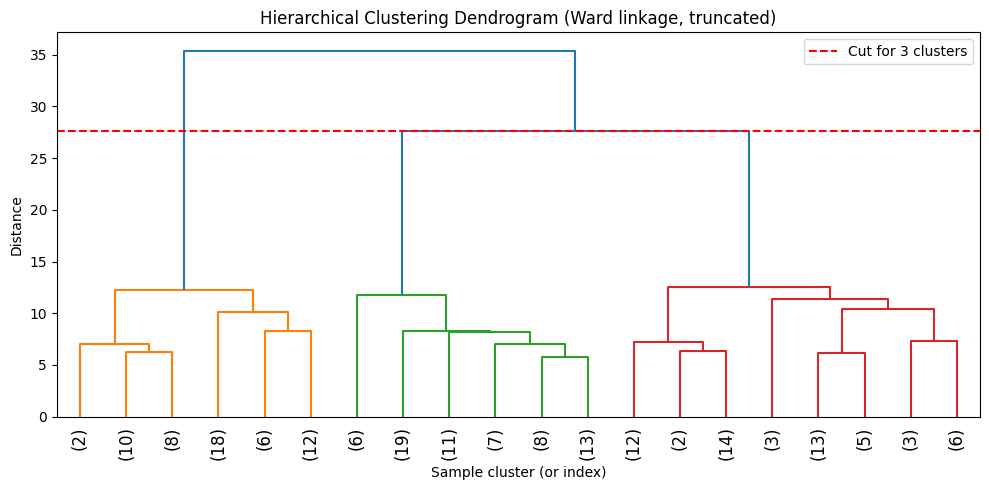

In [13]:
Z = linkage(X_scaled, method="ward")

fig, ax = plt.subplots(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90, ax=ax)
ax.set_title("Hierarchical Clustering Dendrogram (Ward linkage, truncated)")
ax.set_xlabel("Sample cluster (or index)"); ax.set_ylabel("Distance")
ax.axhline(y=Z[-(best_k - 1), 2], color="red", linestyle="--", label=f"Cut for {best_k} clusters")
ax.legend()
plt.tight_layout()
plt.show()

agglo = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
labels_agglo = agglo.fit_predict(X_scaled)

### DBSCAN — density-based clustering with automatic outlier detection


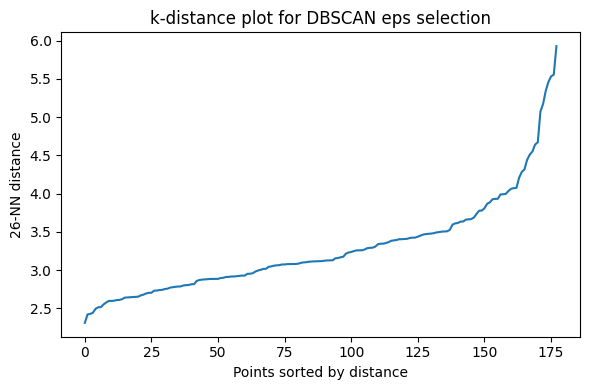

Chosen eps=2.747, min_samples=26 -> 2 clusters, 46 noise points (25.8% of data)


In [14]:
min_samples = 2 * X_scaled.shape[1]
neighbors = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(k_distances)
ax.set_xlabel("Points sorted by distance"); ax.set_ylabel(f"{min_samples}-NN distance")
ax.set_title("k-distance plot for DBSCAN eps selection")
plt.tight_layout()
plt.show()

eps_candidates = np.linspace(np.percentile(k_distances, 10), np.percentile(k_distances, 90), 15)
best_eps, best_sil, best_labels_db = None, -1, None
for eps in eps_candidates:
    db = DBSCAN(eps=eps, min_samples=min_samples)
    labels = db.fit_predict(X_scaled)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    if n_clusters >= 2:
        mask = labels != -1
        if mask.sum() > 1 and len(set(labels[mask])) >= 2:
            sil = silhouette_score(X_scaled[mask], labels[mask])
            if sil > best_sil:
                best_sil, best_eps, best_labels_db = sil, eps, labels

if best_labels_db is None:
    best_eps = np.percentile(k_distances, 50)
    best_labels_db = DBSCAN(eps=best_eps, min_samples=min_samples).fit_predict(X_scaled)

labels_dbscan = best_labels_db
n_clusters_db = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = int(np.sum(labels_dbscan == -1))
print(f"Chosen eps={best_eps:.3f}, min_samples={min_samples} -> "
      f"{n_clusters_db} clusters, {n_noise} noise points ({n_noise/len(labels_dbscan):.1%} of data)")

### Side-by-side evaluation



In [15]:
def evaluate(name, labels):
    mask = labels != -1
    if len(set(labels[mask])) < 2:
        sil, db_score = np.nan, np.nan
    else:
        sil = silhouette_score(X_scaled[mask], labels[mask])
        db_score = davies_bouldin_score(X_scaled[mask], labels[mask])
    ari = adjusted_rand_score(y_true, labels)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(f"{name:22s} | clusters={n_clusters:2d} | silhouette={sil:6.3f} | "
          f"davies-bouldin={db_score:6.3f} | ARI vs true cultivar={ari:6.3f}")

evaluate("K-Means", labels_kmeans)
evaluate("Hierarchical (Ward)", labels_agglo)
evaluate("DBSCAN", labels_dbscan)

K-Means                | clusters= 3 | silhouette= 0.285 | davies-bouldin= 1.389 | ARI vs true cultivar= 0.897
Hierarchical (Ward)    | clusters= 3 | silhouette= 0.277 | davies-bouldin= 1.419 | ARI vs true cultivar= 0.790
DBSCAN                 | clusters= 2 | silhouette= 0.351 | davies-bouldin= 1.106 | ARI vs true cultivar= 0.406


### Visual comparison (PCA projection)



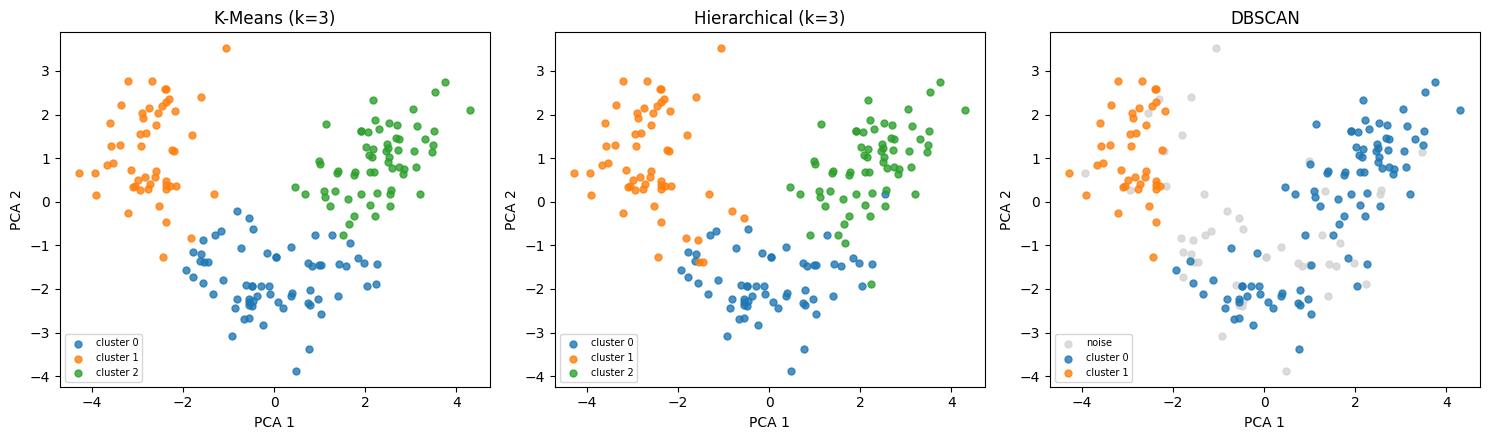

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, labels, title in zip(
    axes,
    [labels_kmeans, labels_agglo, labels_dbscan],
    [f"K-Means (k={best_k})", f"Hierarchical (k={best_k})", "DBSCAN"]
):
    for lbl in sorted(set(labels)):
        mask = labels == lbl
        color = "lightgray" if lbl == -1 else None
        marker_label = "noise" if lbl == -1 else f"cluster {lbl}"
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=25, alpha=0.8, label=marker_label, c=color)
    ax.set_title(title); ax.set_xlabel("PCA 1"); ax.set_ylabel("PCA 2")
    ax.legend(fontsize=7, loc="best")
plt.tight_layout()
plt.show()

## Summary

| Stage | What we did | Key scikit-learn tools |
|---|---|---|
| Preprocessing | Imputation, scaling, one-hot encoding on mixed-type data | `SimpleImputer`, `StandardScaler`, `OneHotEncoder`, `ColumnTransformer` |
| Pipelines | Combined preprocessing + model into one leak-proof object | `Pipeline` |
| Model building | Compared Logistic Regression vs Random Forest with tuning | `GridSearchCV`, `StratifiedKFold` |
| Evaluation | Accuracy, precision, recall, F1, ROC-AUC, confusion matrix | `classification_report`, `RocCurveDisplay`, `ConfusionMatrixDisplay` |
| Interpretation | Coefficients / feature importances + model-agnostic check | `.coef_`, `.feature_importances_`, `permutation_importance` |
| Clustering | K-Means, Hierarchical, DBSCAN with principled parameter selection | `KMeans`, `AgglomerativeClustering`, `DBSCAN`, `linkage`/`dendrogram` |
| Cluster evaluation | Internal metrics (no ground truth needed) + external check | `silhouette_score`, `davies_bouldin_score`, `adjusted_rand_score` |

**Exercises to extend this notebook:**
1. Try `SVC` as a third candidate model in Part A's grid search.
2. Add `class_weight="balanced"` and see how precision/recall trade off on the minority class.
3. In Part B, try DBSCAN with different `min_samples` values and observe how the noise fraction changes.
4. Use `AgglomerativeClustering` with `linkage="average"` or `"complete"` instead of `"ward"` and compare
   silhouette scores.
